In [4]:
import os, glob, zipfile, urllib.request
import pandas as pd

RAW = "/content/EduPredict/data/raw"
PROC = "/content/EduPredict/data/processed"
os.makedirs(RAW, exist_ok=True)
os.makedirs(PROC, exist_ok=True)

URL = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"

def find_csv():
    hits = glob.glob("/content/**/data.csv", recursive=True)
    return hits[0] if hits else None

path = find_csv()
if path is None:
    zip_path = f"{RAW}/dropout.zip"
    req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=60) as r, open(zip_path, "wb") as f:
        f.write(r.read())
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(f"{RAW}/dropout")
    path = find_csv()
print("Using:", path)

df = pd.read_csv(path, sep=";")
df.columns = df.columns.str.strip().str.replace("Nacionality", "Nationality", regex=False)
df = df.drop_duplicates().reset_index(drop=True)

categorical = ["Marital status", "Application mode", "Application order", "Course",
               "Previous qualification", "Nationality", "Mother's qualification",
               "Father's qualification", "Mother's occupation", "Father's occupation"]
binary = ["Daytime/evening attendance", "Displaced", "Educational special needs",
          "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
for c in binary:
    assert set(df[c].unique()) <= {0, 1}, f"{c} has values other than 0/1"
for c in categorical + binary:
    df[c] = df[c].astype("int64")

df["Target"] = df["Target"].astype(str).str.strip().str.capitalize()
assert set(df["Target"].unique()) == {"Dropout", "Enrolled", "Graduate"}
assert df.isnull().sum().sum() == 0

df.to_csv(f"{PROC}/dropout_clean.csv", index=False)
print(pd.read_csv(f"{PROC}/dropout_clean.csv").shape)
print(df["Target"].value_counts().to_dict())

Using: /content/EduPredict/data/raw/dropout/data.csv
(4424, 37)
{'Graduate': 2209, 'Dropout': 1421, 'Enrolled': 794}


In [5]:
import os, json, warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, roc_auc_score

warnings.filterwarnings("ignore")

PROC = "/content/EduPredict/data/processed"
MODELS = "/content/EduPredict/models"
os.makedirs(MODELS, exist_ok=True)

if not os.path.exists(f"{PROC}/dropout_clean.csv"):
    raise FileNotFoundError("dropout_clean.csv missing. Colab was reset: re-run Phase 3 (Cells 1-8) first.")

df = pd.read_csv(f"{PROC}/dropout_clean.csv")
df["Dropout_flag"] = (df["Target"] == "Dropout").astype(int)

print(df["Dropout_flag"].value_counts().to_dict(), f"-> {df['Dropout_flag'].mean() * 100:.1f}% dropout")

{0: 3003, 1: 1421} -> 32.1% dropout


In [6]:
# Check near-constant columns (one value covers >95% of students)
candidates = df.drop(columns=["Target", "Dropout_flag"])
near_constant = [c for c in candidates.columns if candidates[c].value_counts(normalize=True).iloc[0] > 0.95]
print("Near-constant:", near_constant)

DROPPED = ["Nationality", "International", "Educational special needs",
           "Mother's qualification", "Father's qualification",
           "Mother's occupation", "Father's occupation",
           "Unemployment rate", "Inflation rate", "GDP"]

ENROLLMENT = ["Marital status", "Application mode", "Application order", "Course",
              "Daytime/evening attendance", "Previous qualification",
              "Previous qualification (grade)", "Admission grade", "Displaced",
              "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder",
              "Age at enrollment"]

SEM1 = [f"Curricular units 1st sem ({s})" for s in
        ["credited", "enrolled", "evaluations", "approved", "grade", "without evaluations"]]
SEM2 = [c.replace("1st", "2nd") for c in SEM1]

FEATURE_SETS = {
    "enrollment": ENROLLMENT,
    "sem1": ENROLLMENT + SEM1,
    "full": ENROLLMENT + SEM1 + SEM2,
}

# Safety check: every column is either used or deliberately dropped
all_features = set(df.columns) - {"Target", "Dropout_flag"}
assert set(FEATURE_SETS["full"]) | set(DROPPED) == all_features, "Some column is unaccounted for!"
assert not set(FEATURE_SETS["full"]) & set(DROPPED)
assert "Target" not in FEATURE_SETS["full"] and "Dropout_flag" not in FEATURE_SETS["full"]  # no target leakage

print({k: len(v) for k, v in FEATURE_SETS.items()})


Near-constant: ['Nationality', 'Educational special needs', 'International']
{'enrollment': 14, 'sem1': 20, 'full': 26}


In [7]:
CATEGORICAL = ["Marital status", "Application mode", "Application order", "Course", "Previous qualification"]
BINARY = ["Daytime/evening attendance", "Displaced", "Debtor",
          "Tuition fees up to date", "Gender", "Scholarship holder"]
NUMERIC = [c for c in FEATURE_SETS["full"] if c not in CATEGORICAL + BINARY]

print(len(NUMERIC), "numeric features")
print(NUMERIC)

15 numeric features
['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']


In [8]:
def build_preprocessor(feature_list):
    cat = [c for c in feature_list if c in CATEGORICAL]
    binary = [c for c in feature_list if c in BINARY]
    num = [c for c in feature_list if c in NUMERIC]
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num),                       # scale numbers
            ("bin", "passthrough", binary),                       # keep 0/1 as is
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=20), cat),        # codes -> one-hot columns
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

In [9]:
X = df[FEATURE_SETS["full"]]
y = df["Dropout_flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print("Dropout share  train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

(3539, 26) (885, 26)
Dropout share  train: 0.321 | test: 0.321


In [10]:
sem1_cols = FEATURE_SETS["sem1"]
prep = build_preprocessor(sem1_cols).fit(X_train[sem1_cols])     # fit on TRAIN only

scaler = prep.named_transformers_["num"]
print("Scaler learned from train:", dict(zip(scaler.feature_names_in_[:3], scaler.mean_[:3].round(2))))
print("Admission grade mean (train):", round(X_train["Admission grade"].mean(), 2),
      "| (all data, NOT used):", round(X["Admission grade"].mean(), 2))

for name, cols in FEATURE_SETS.items():
    p = build_preprocessor(cols).fit(X_train[cols])
    print(f"{name:10s}: {len(cols)} features -> {len(p.get_feature_names_out())} model columns")

Scaler learned from train: {'Previous qualification (grade)': np.float64(132.68), 'Admission grade': np.float64(126.99), 'Age at enrollment': np.float64(23.19)}
Admission grade mean (train): 126.99 | (all data, NOT used): 126.98
enrollment: 14 features -> 60 model columns
sem1      : 20 features -> 66 model columns
full      : 26 features -> 72 model columns


In [11]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
print("Train non-dropout:", neg, "| dropout:", pos, "| ratio:", round(neg / pos, 2))
print("Balanced class weights -> non-dropout:", round(len(y_train) / (2 * neg), 2),
      "| dropout:", round(len(y_train) / (2 * pos), 2))

Train non-dropout: 2402 | dropout: 1137 | ratio: 2.11
Balanced class weights -> non-dropout: 0.74 | dropout: 1.56


In [12]:
for name, cols in FEATURE_SETS.items():
    model = Pipeline([
        ("prep", build_preprocessor(cols)),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced")),
    ]).fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    prob = model.predict_proba(X_test[cols])[:, 1]
    print(f"{name:10s} dropout recall: {recall_score(y_test, pred):.3f} | ROC-AUC: {roc_auc_score(y_test, prob):.3f}")

enrollment dropout recall: 0.736 | ROC-AUC: 0.836
sem1       dropout recall: 0.810 | ROC-AUC: 0.912
full       dropout recall: 0.831 | ROC-AUC: 0.933


In [13]:
config = {
    "target": "Dropout_flag (1 = Dropout, 0 = Graduate or Enrolled)",
    "feature_sets": FEATURE_SETS,
    "categorical": CATEGORICAL,
    "binary": BINARY,
    "numeric": NUMERIC,
    "dropped_features": DROPPED,
    "split": {"test_size": 0.2, "random_state": 42, "stratify": True},
    "primary_feature_set": "sem1",
}
with open(f"{MODELS}/feature_config.json", "w") as f:
    json.dump(config, f, indent=2)

X_train.assign(Dropout_flag=y_train).to_csv(f"{PROC}/train.csv", index=False)
X_test.assign(Dropout_flag=y_test).to_csv(f"{PROC}/test.csv", index=False)

print(pd.read_csv(f"{PROC}/train.csv").shape, pd.read_csv(f"{PROC}/test.csv").shape)

(3539, 27) (885, 27)


In [14]:
import shutil
from google.colab import files

os.makedirs("/content/phase5_out/models", exist_ok=True)
os.makedirs("/content/phase5_out/data_processed", exist_ok=True)
shutil.copy(f"{MODELS}/feature_config.json", "/content/phase5_out/models/")
shutil.copy(f"{PROC}/train.csv", "/content/phase5_out/data_processed/")
shutil.copy(f"{PROC}/test.csv", "/content/phase5_out/data_processed/")
shutil.make_archive("/content/phase5_out", "zip", "/content/phase5_out")
files.download("/content/phase5_out.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import os, glob, zipfile, urllib.request, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RAW = "/content/EduPredict/data/raw"
PROC = "/content/EduPredict/data/processed"
FIG = "/content/EduPredict/screenshots/models"
REP = "/content/EduPredict/reports"
for p in (RAW, PROC, FIG, REP):
    os.makedirs(p, exist_ok=True)

# ---------- 1. Get the cleaned dropout data (rebuild if missing) ----------
clean_path = f"{PROC}/dropout_clean.csv"
if not os.path.exists(clean_path):
    URL = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
    hits = glob.glob("/content/**/data.csv", recursive=True)
    if not hits:
        zip_path = f"{RAW}/dropout.zip"
        req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as r, open(zip_path, "wb") as f:
            f.write(r.read())
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(f"{RAW}/dropout")
        hits = glob.glob("/content/**/data.csv", recursive=True)
    raw = pd.read_csv(hits[0], sep=";")
    raw.columns = raw.columns.str.strip().str.replace("Nacionality", "Nationality", regex=False)
    raw = raw.drop_duplicates().reset_index(drop=True)
    raw["Target"] = raw["Target"].astype(str).str.strip().str.capitalize()
    assert set(raw["Target"].unique()) == {"Dropout", "Enrolled", "Graduate"}
    assert raw.isnull().sum().sum() == 0
    raw.to_csv(clean_path, index=False)
    print("Rebuilt dropout_clean.csv")

df = pd.read_csv(clean_path)
df["Dropout_flag"] = (df["Target"] == "Dropout").astype(int)

# ---------- 2. Feature sets (same as Phase 5) ----------
ENROLLMENT = ["Marital status", "Application mode", "Application order", "Course",
              "Daytime/evening attendance", "Previous qualification",
              "Previous qualification (grade)", "Admission grade", "Displaced",
              "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder",
              "Age at enrollment"]
SEM1 = [f"Curricular units 1st sem ({s})" for s in
        ["credited", "enrolled", "evaluations", "approved", "grade", "without evaluations"]]
SEM2 = [c.replace("1st", "2nd") for c in SEM1]
FEATURE_SETS = {"enrollment": ENROLLMENT, "sem1": ENROLLMENT + SEM1, "full": ENROLLMENT + SEM1 + SEM2}

CATEGORICAL = ["Marital status", "Application mode", "Application order", "Course", "Previous qualification"]
BINARY = ["Daytime/evening attendance", "Displaced", "Debtor",
          "Tuition fees up to date", "Gender", "Scholarship holder"]
NUMERIC = [c for c in FEATURE_SETS["full"] if c not in CATEGORICAL + BINARY]

def build_preprocessor(feature_list):
    cat = [c for c in feature_list if c in CATEGORICAL]
    binary = [c for c in feature_list if c in BINARY]
    num = [c for c in feature_list if c in NUMERIC]
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num),
            ("bin", "passthrough", binary),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=20, sparse_output=False), cat),
        ],
        remainder="drop", sparse_threshold=0, verbose_feature_names_out=False,
    )

# ---------- 3. Same split as Phase 5 ----------
X = df[FEATURE_SETS["full"]]
y = df["Dropout_flag"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(3539, 26) (885, 26)


In [16]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = dummy.predict(X_test)
print("Dummy model (always says 'not dropout')")
print("  Accuracy:", round(accuracy_score(y_test, pred), 3))
print("  Dropout recall:", recall_score(y_test, pred))

Dummy model (always says 'not dropout')
  Accuracy: 0.679
  Dropout recall: 0.0


In [17]:
def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                class_weight="balanced_subsample",
                                                random_state=42, n_jobs=-1),
        "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    }

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

rows = []
for fs, cols in FEATURE_SETS.items():
    for name, model in make_models().items():
        pipe = Pipeline([("prep", build_preprocessor(cols)), ("clf", model)])
        res = cross_validate(pipe, X_train[cols], y_train, cv=cv, scoring=scoring)
        rows.append({"feature_set": fs, "model": name,
                     **{k: round(res[f"test_{k}"].mean(), 3) for k in scoring},
                     "recall_std": round(res["test_recall"].std(), 3)})

cv_results = pd.DataFrame(rows)
print(cv_results.to_string(index=False))

feature_set               model  accuracy  precision  recall    f1  roc_auc  recall_std
 enrollment Logistic Regression     0.743      0.586   0.689 0.633    0.808       0.027
 enrollment       Random Forest     0.758      0.631   0.591 0.610    0.805       0.028
 enrollment   Gradient Boosting     0.736      0.581   0.638 0.608    0.787       0.028
       sem1 Logistic Regression     0.840      0.736   0.788 0.761    0.896       0.019
       sem1       Random Forest     0.847      0.788   0.717 0.750    0.893       0.020
       sem1   Gradient Boosting     0.832      0.739   0.737 0.738    0.885       0.031
       full Logistic Regression     0.861      0.768   0.814 0.790    0.914       0.023
       full       Random Forest     0.869      0.828   0.747 0.785    0.914       0.018
       full   Gradient Boosting     0.858      0.785   0.770 0.777    0.906       0.015


In [19]:
fitted = {}
test_rows = []
for fs, cols in FEATURE_SETS.items():
    for name, model in make_models().items():
        pipe = Pipeline([("prep", build_preprocessor(cols)), ("clf", model)]).fit(X_train[cols], y_train)
        fitted[(fs, name)] = pipe
        pred = pipe.predict(X_test[cols])
        prob = pipe.predict_proba(X_test[cols])[:, 1]
        test_rows.append({"feature_set": fs, "model": name,
                          "accuracy": round(accuracy_score(y_test, pred), 3),
                          "precision": round(precision_score(y_test, pred), 3),
                          "recall": round(recall_score(y_test, pred), 3),
                          "f1": round(f1_score(y_test, pred), 3),
                          "roc_auc": round(roc_auc_score(y_test, prob), 3)})

test_results = pd.DataFrame(test_rows)
print(test_results.to_string(index=False))

feature_set               model  accuracy  precision  recall    f1  roc_auc
 enrollment Logistic Regression     0.754      0.594   0.736 0.657    0.836
 enrollment       Random Forest     0.776      0.662   0.620 0.640    0.829
 enrollment   Gradient Boosting     0.758      0.613   0.669 0.640    0.809
       sem1 Logistic Regression     0.858      0.762   0.810 0.785    0.912
       sem1       Random Forest     0.854      0.802   0.725 0.762    0.909
       sem1   Gradient Boosting     0.862      0.777   0.799 0.788    0.909
       full Logistic Regression     0.881      0.805   0.831 0.818    0.933
       full       Random Forest     0.882      0.841   0.782 0.810    0.930
       full   Gradient Boosting     0.866      0.787   0.796 0.792    0.927


In [22]:
PRIMARY = "sem1"
cols = FEATURE_SETS[PRIMARY]
print("fitted models available:", len(fitted))

fitted models available: 9


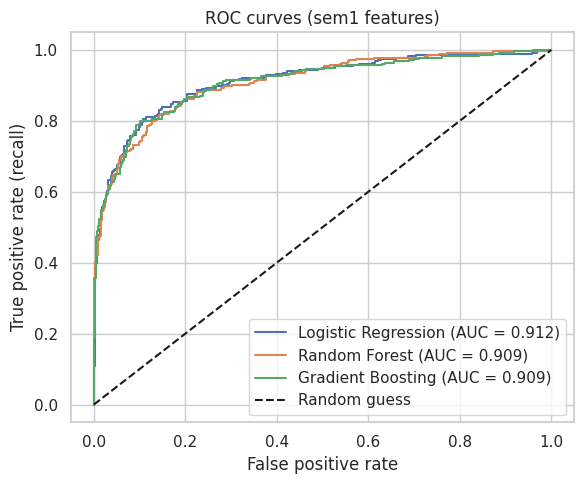

In [23]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in make_models():
    prob = fitted[(PRIMARY, name)].predict_proba(X_test[cols])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title(f"ROC curves ({PRIMARY} features)"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/roc_curves.png", dpi=150)
plt.show()

In [24]:
pipe = Pipeline([("prep", build_preprocessor(cols)),
                 ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
oof = cross_val_predict(pipe, X_train[cols], y_train, cv=cv, method="predict_proba")[:, 1]
test_prob = fitted[(PRIMARY, "Logistic Regression")].predict_proba(X_test[cols])[:, 1]

rows = []
for th in [0.3, 0.4, 0.5, 0.6]:
    rows.append({"threshold": th,
                 "train_cv_recall": round(recall_score(y_train, oof >= th), 3),
                 "train_cv_precision": round(precision_score(y_train, oof >= th), 3),
                 "test_recall": round(recall_score(y_test, test_prob >= th), 3),
                 "test_precision": round(precision_score(y_test, test_prob >= th), 3)})
print(pd.DataFrame(rows).to_string(index=False))

 threshold  train_cv_recall  train_cv_precision  test_recall  test_precision
       0.3            0.882               0.586        0.894           0.615
       0.4            0.842               0.661        0.852           0.680
       0.5            0.788               0.734        0.810           0.762
       0.6            0.728               0.790        0.746           0.819


Lowest dropout risk: {'Curricular units 1st sem (approved)': -2.25, 'Tuition fees up to date': -2.21, 'Application mode_15': -1.13, 'Course_171': -1.08, 'Previous qualification_12': -0.7, 'Course_9003': -0.65, 'Scholarship holder': -0.56, 'Course_9238': -0.52}
Highest dropout risk: {'Course_9556': 0.51, 'Course_9254': 0.53, 'Curricular units 1st sem (credited)': 0.66, 'Debtor': 0.71, 'Curricular units 1st sem (enrolled)': 0.82, 'Course_9130': 0.88, 'Previous qualification_2': 1.05, 'Course_9853': 1.14}
Random Forest top 10: {'Curricular units 1st sem (approved)': 0.205, 'Curricular units 1st sem (grade)': 0.147, 'Tuition fees up to date': 0.083, 'Age at enrollment': 0.069, 'Curricular units 1st sem (evaluations)': 0.063, 'Admission grade': 0.061, 'Previous qualification (grade)': 0.05, 'Curricular units 1st sem (enrolled)': 0.033, 'Scholarship holder': 0.03, 'Debtor': 0.03}


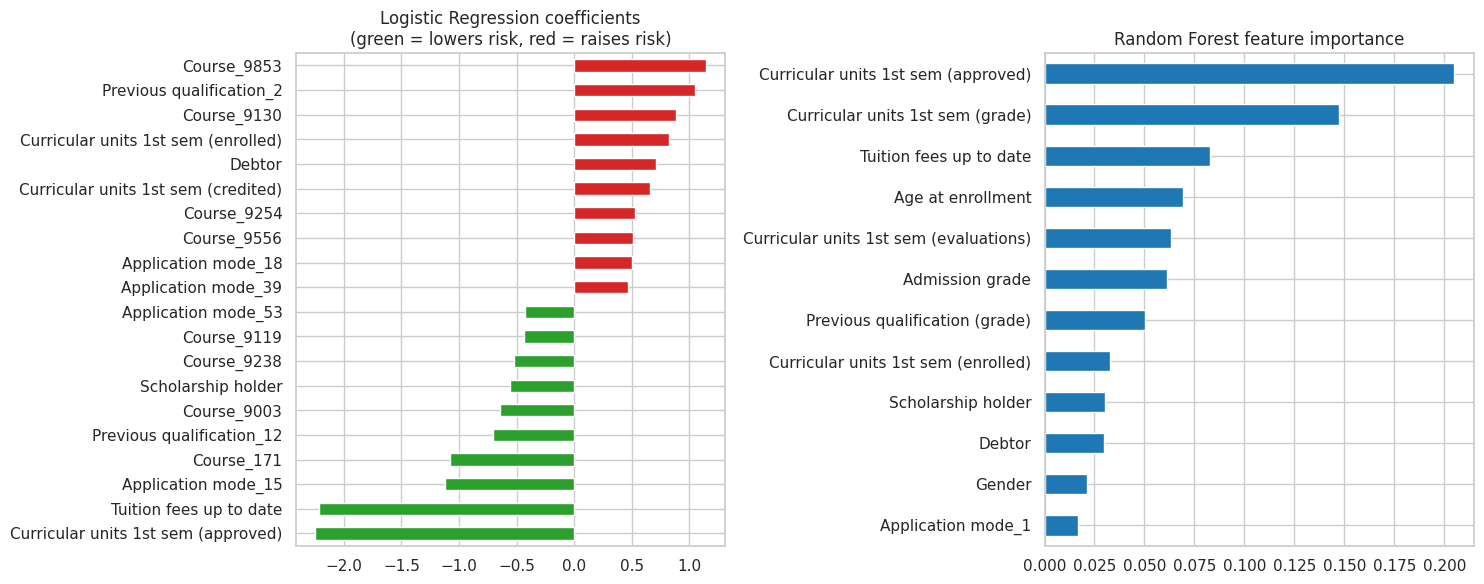

In [25]:
# Logistic Regression: coefficients (positive = raises dropout risk, negative = lowers it)
lr = fitted[(PRIMARY, "Logistic Regression")]
names = lr[:-1].get_feature_names_out()
coef = pd.Series(lr[-1].coef_[0], index=names).sort_values()
print("Lowest dropout risk:", coef.head(8).round(2).to_dict())
print("Highest dropout risk:", coef.tail(8).round(2).to_dict())

# Random Forest: importance
rf = fitted[(PRIMARY, "Random Forest")]
imp = pd.Series(rf[-1].feature_importances_, index=rf[:-1].get_feature_names_out()).sort_values(ascending=False)
print("Random Forest top 10:", imp.head(10).round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
extremes = pd.concat([coef.head(10), coef.tail(10)])
extremes.plot(kind="barh", ax=axes[0], color=["#2ca02c" if v < 0 else "#d62728" for v in extremes])
axes[0].set_title("Logistic Regression coefficients\n(green = lowers risk, red = raises risk)")
imp.head(12)[::-1].plot(kind="barh", ax=axes[1], color="#1f77b4")
axes[1].set_title("Random Forest feature importance")
plt.tight_layout()
plt.savefig(f"{FIG}/feature_importance.png", dpi=150)
plt.show()

In [26]:
cv_results.to_csv(f"{REP}/cv_results.csv", index=False)
test_results.to_csv(f"{REP}/test_results.csv", index=False)

import shutil
from google.colab import files
shutil.make_archive("/content/phase6_out", "zip", "/content/EduPredict")
files.download("/content/phase6_out.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>